# Lunar Lander - khung TODO tự làm

Mục tiêu: tàu đáp xuống giữa 2 lá cờ. Solved khi **trung bình 100 episode >= 200**.
Thuật toán giống Acrobot (DQN + replay buffer + target network), nên cứ mở `acrobot.ipynb` ra đối chiếu rồi tự hiểu chỗ nào phải đổi.

Quy ước: `TODO` = việc m làm, `KEYWORD` = cụm để search (Google / docs / hỏi AI), `HỎI` = câu tự trả lời cho hiểu.

## 0. Cài đặt môi trường
- KEYWORD: `gymnasium box2d install windows`, `swig`, `Microsoft C++ Build Tools`
- Gợi ý: gói cần là `gymnasium[box2d]`. Lỗi build thì thường thiếu swig hoặc C++ Build Tools.
- TODO: cài xong thì chạy cell dưới để check.
- Lưu ý: kiểm tra `gym.__version__`. Tên env là `LunarLander-v2` hay `v3` tùy version gymnasium.

In [2]:
# TODO: import các thư viện cần dùng (xem cell đầu của acrobot.ipynb)
import random
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch 
import torch.nn as nn
import torch.optim as optim 
# TODO: tạo env LunarLander, in ra observation_space và action_space
# KEYWORD: gymnasium LunarLander observation space, gymnasium LunarLander action space
# HỎI: 8 số của state là gì? 4 action là gì? Reward được tính thế nào (reward shaping)?
env = gym.make("LunarLander-v2")
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n
print(env.observation_space.shape)

(8,)


Observation Space state của môi trường này là 8D vector, bao gồm:
- Coordinates of the lander in `x` & `y`
- Linear velocities in `x` & `y`
- Angle
- Angular velocity
- 2 Booleans represent whether each leg is in contact with the ground or not.

Cách xây dựng reward của env:
Sau mỗi step sẽ có một phần thưởng. Tổng phần thưởng của 1 episode là tổng phần thưởng của tất cả các steps trong episode đó.
Với mỗi step, phần thưởng được tính như sau:
- is increased/decreased the closer/further the lander is to the landing pad.
- is increased/decreased the slower/faster the lander is moving
- is decreased the more the lander is tilted (angle not horizontal)
- is increased by 10 points for each leg that is in contact with the ground.
- is decreased by 0.03 points each frame a side engine is firing.
- is decreased by 0.3 points each frame the main engine is firing.

Mỗi episode sẽ nhận thêm phần thưởng -100 hoặc +100 điểm khi crashing hoặc landing an toàn.

1 Episode được coi là giải pháp (có thể chấp nhận) nếu nó đạt được ít nhất 200 points.

### Starting State
The lander starts at the top center of the viewport with a random initial force applied to its center of mass.

## 1. Q-Network
- TODO: viết class QNetwork (nn.Module), input = state_dim, output = action_dim.
- KEYWORD: `pytorch nn.Module nn.Sequential nn.Linear`
- HỎI: tại sao output là 4 số mà không phải 1 số? Tại sao lớp cuối không có ReLU?
- Thử: so với Acrobot, state nhiều hơn thì nên để hidden size lớn hơn hay nhỏ hơn?

In [3]:
# TODO: class QNetwork
class QNetwork(nn.Module):
    def __init__(self, state_dim, action_dim ,*args, **kwargs):
        super(QNetwork, self).__init__(*args, **kwargs)
        self.fc = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, action_dim)
        )
    
    def forward(self, x):
        return self.fc(x)

## 2. Khởi tạo hyperparameter
- TODO: tạo model, optimizer, loss, target_model, replay_buffer và các biến hyperparameter.
- KEYWORD: `copy.deepcopy pytorch model`, `collections.deque maxlen`, `SmoothL1Loss vs MSELoss`, `Adam learning rate`
- HỎI: target network để làm gì? Nếu bỏ đi thì chuyện gì xảy ra?
- HỎI: replay buffer để làm gì? Tại sao phải lấy mẫu ngẫu nhiên?
- Gợi ý chỉnh so với Acrobot: buffer lớn hơn, epsilon_min thấp hơn, episodes nhiều hơn, bắt đầu học sau khi buffer đủ đầy.

In [4]:
import copy
from collections import deque

# TODO: model, optimizer, criterion
model = QNetwork(state_dim=state_dim, action_dim=action_dim)
optimizer = optim.Adam(model.parameters(), lr=5e-4)
criterion = nn.SmoothL1Loss()
print(model)
# TODO: target_model + tần suất cập nhật
target_model = copy.deepcopy(model)
target_model.eval()
target_update_every = 500

# TODO: replay_buffer, batch_size
replay_buffer = deque(maxlen=50000)
batch_size = 128

# TODO: episodes, gamma, epsilon, epsilon_decay, epsilon_min
episodes = 500
gamma = 0.99
epsilon = 1.0
epsilon_decay = 0.995
epsilon_min = 0.05

# TODO: scores = [], total_steps = 0
scores = []
total_steps = 0

QNetwork(
  (fc): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
)


## 3. Vòng lặp huấn luyện
Chia nhỏ ra làm từng bước, làm xong bước nào chạy thử bước đó:
1. Chọn action: epsilon-greedy. KEYWORD: `epsilon greedy exploration exploitation`, `torch.argmax`, `torch.no_grad`
2. Chạy env: `env.step`. HỎI: `terminated` khác `truncated` thế nào? Cái nào nên đưa vào `done` khi tính target?
3. Lưu transition vào buffer: (state, action, reward, next_state, done)
4. Lấy batch ra học. KEYWORD: `random.sample`, `zip(*batch)`, `torch.FloatTensor np.array`
5. Tính target Bellman: `r + gamma * max Q_target(s') * (1 - done)`. KEYWORD: `DQN target Bellman equation`, `tensor.max(dim=1)`
6. Lấy Q của action đã chọn. KEYWORD: `torch.gather`. HỎI: shape của tensor ở mỗi bước là gì? In ra để kiểm tra.
7. Tính loss + cập nhật: `zero_grad`, `backward`, `step`. KEYWORD: `clip_grad_norm_ gradient clipping`
8. Cập nhật target_model định kỳ. KEYWORD: `load_state_dict`
9. Cuối episode: giảm epsilon, lưu score, in log. Tự thêm điều kiện dừng khi trung bình 100 episode >= 200.

In [5]:
print("Training...")
# TODO: vòng for episode
for e in range(episodes):
    state, _ = env.reset()
    total_reward = 0
    done = False
    
#   TODO: vòng while not done
    while not done:
#       TODO: chọn action
        if random.random() < epsilon:
            action = env.action_space.sample()
        else:
            with torch.no_grad():
                    state_t = torch.FloatTensor(state)
                    q_value = model(state_t)
                    action = torch.argmax(q_value).item()
                    
#       TODO: env.step + lưu buffer
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        replay_buffer.append((state, action, reward, next_state, float(terminated)))
        
        state = next_state
        total_reward += reward
        total_steps += 1
        
        if len(replay_buffer) >= batch_size:
            batch = random.sample(replay_buffer, batch_size)
            states, actions, rewards, next_states, dones = zip(*batch)
            states_t = torch.FloatTensor(states)
            # print(states_t.shape)
            actions_t = torch.LongTensor(actions).unsqueeze(1)
            # print(actions_t.shape)
            rewards_t = torch.FloatTensor(rewards)
            next_states_t = torch.FloatTensor(next_states)
            dones_t = torch.FloatTensor(dones)
            
            # TODO: học từ batch
            with torch.no_grad():
                max_next_q = target_model(next_states_t).max(dim=1)[0]
                target = rewards_t + gamma * max_next_q * (1 - dones_t)
            
            current_q = model(states_t).gather(1, actions_t).squeeze(1)
            
            # loss = criterion
            loss = criterion(current_q, target)
            
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            optimizer.step()
        
        # TODO: cập nhật target network
        if total_steps % target_update_every == 0:
            target_model.load_state_dict(model.state_dict())

#   TODO: giảm epsilon, lưu score, in log
    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    scores.append(total_reward)
    print(f"Episode: {e+1}/{episodes} | Score: {total_reward} | Epsilon: {epsilon:.2f}")

# TODO: env.close() và lưu model
env.close()
# KEYWORD: pytorch save state_dict

Training...
Episode: 1/500 | Score: -24.46200485443248 | Epsilon: 0.99
Episode: 2/500 | Score: -101.90548866472254 | Epsilon: 0.99


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_19400\349626734.py:31: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:255.)
  states_t = torch.FloatTensor(states)


Episode: 3/500 | Score: -85.75771445681343 | Epsilon: 0.99
Episode: 4/500 | Score: -379.2095247594226 | Epsilon: 0.98
Episode: 5/500 | Score: -165.483670367071 | Epsilon: 0.98
Episode: 6/500 | Score: -203.15511262877112 | Epsilon: 0.97
Episode: 7/500 | Score: -416.23253775583703 | Epsilon: 0.97
Episode: 8/500 | Score: -152.6636237611861 | Epsilon: 0.96
Episode: 9/500 | Score: -258.53842988357997 | Epsilon: 0.96
Episode: 10/500 | Score: -229.11538609570687 | Epsilon: 0.95
Episode: 11/500 | Score: -152.27705996334595 | Epsilon: 0.95
Episode: 12/500 | Score: -72.89694643069225 | Epsilon: 0.94
Episode: 13/500 | Score: -128.79506547289466 | Epsilon: 0.94
Episode: 14/500 | Score: -111.21914436082282 | Epsilon: 0.93
Episode: 15/500 | Score: -48.5600489102755 | Epsilon: 0.93
Episode: 16/500 | Score: -388.85207938146766 | Epsilon: 0.92
Episode: 17/500 | Score: -129.15482027194113 | Epsilon: 0.92
Episode: 18/500 | Score: -125.02497033504653 | Epsilon: 0.91
Episode: 19/500 | Score: -65.1910929135

Trong env, ta phải thiết lập env.step(), ở đây thư viện gymnasium đã hỗ trợ sẵn.
Đọc documents ở đây để hiểu thêm: [env.step()](https://gymnasium.farama.org/api/env/#gymnasium.Env.step)

## 4. Vẽ đồ thị
- TODO: vẽ score theo episode + đường trung bình 100 episode + đường ngang y=200.
- KEYWORD: `matplotlib plot axhline`, `numpy moving average`
- HỎI: nhìn đồ thị, agent có đang học thật không hay chỉ may mắn?

AttributeError: 'list' object has no attribute 'mean'

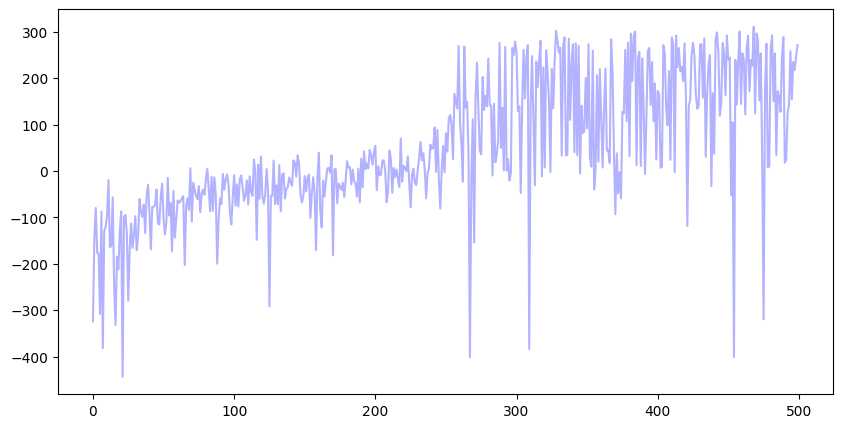

In [167]:
# TODO: plot
plt.figure(figsize=(10, 5))
plt.plot(
    scores, label="Score", alpha=0.3, color="blue"
)  # Điểm gốc (làm mờ đi để dễ nhìn đường trung bình)
plt.plot(
    scores.mean(), label="Mean (100 episodes)", color="orange", linewidth=2
)  # Đường trung bình 100 tập
plt.axhline(
    y=200, color="red", linestyle="--", label="Target (y=200)"
)  # Đường ngang mốc mục tiêu mô hình cần đạt

plt.title("Quá trình học tập của Agent (Score theo Episode)")
plt.xlabel("Episode")
plt.ylabel("Total Score")
plt.legend()  # Hiển thị chú thích các đường
plt.grid(True, linestyle=":", alpha=0.6)  # Thêm lưới tọa độ cho dễ quan sát
plt.show()

## 5. Đánh giá
- TODO: viết hàm evaluate (xem acrobot): epsilon = 0, không tính gradient, chạy n episode, trả về list score.
- KEYWORD: `model.eval() model.train()`, `gymnasium render_mode human rgb_array`
- HỎI: tại sao lúc đánh giá không dùng epsilon?

In [1]:
# TODO: def evaluate(...)
def evaluate(model, n_episodes=20, render=False):
# TODO: chạy 20 episode không render, in mean +/- std
    eval_env = gym.make("LunarLander-v2", render_mode="human" if render else None)
    model.eval()
    results = []
    for _ in range(n_episodes):
        state, _ = eval_env.reset()
        done, total = False, 0
        while not done:
            with torch.no_grad():
                action = model(torch.FloatTensor(state)).argmax().item()
            state, reward, terminated, truncated, _ = eval_env.step(action)
            done = terminated or truncated
            total += reward
        results.append(total)
    eval_env.close()
    model.train()
    return results

# TODO: chạy 3 episode có render để xem agent chơi
evaluate(model, n_episodes=3, render=True)    

NameError: name 'model' is not defined

# Use PPO